[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/vector-spaces-and-subspaces/notebook.ipynb)

# Vector Spaces and Subspaces: hands-on

This notebook goes with the [topic README](README.md). You will test sets for the subspace rules, look at a column space and a nullspace in 3D, row reduce a matrix to $R$ from scratch, read special solutions off $R$, build the complete solution to $A\mathbf{x} = \mathbf{b}$, and meet a data matrix with a hidden redundant column. It uses NumPy, Matplotlib, `scipy.linalg`, and SymPy (only to double-check our own row reduction), and runs in a few seconds on a CPU.

Run the cells from top to bottom. After each demo, change a number and run it again.

In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as sla
import sympy as sp
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=3, suppress=True)

## 1. The subspace test as code

A set $S$ of vectors is a **subspace** if it contains the zero vector, adding two members stays inside, and scaling a member by any number stays inside. A computer cannot check *every* vector, but it can try many random ones. A single failure proves that a set is **not** a subspace. Passing all the tests is evidence, and the reasoning in the README makes it a proof.

Each candidate below comes with a membership test `contains` and a way to draw random members `sample`.

In [2]:
def check_subspace(name, contains, sample, trials=200, seed=0):
    """Try the three subspace rules on random members and report the first failure."""
    rng = np.random.default_rng(seed)
    if not contains(np.zeros_like(sample(rng))):
        return f"{name:28s} NOT a subspace: it misses the zero vector"
    for _ in range(trials):
        u, v = sample(rng), sample(rng)
        c = rng.normal() * 3
        if not contains(u + v):
            return f"{name:28s} NOT a subspace: {np.round(u, 2)} + {np.round(v, 2)} leaves the set"
        if not contains(c * u):
            return f"{name:28s} NOT a subspace: {c:.2f} * {np.round(u, 2)} leaves the set"
    return f"{name:28s} passes all {trials} random trials"


tol = 1e-9
candidates = {
    "line y = 2x":            (lambda p: abs(p[1] - 2 * p[0]) < tol,           lambda r: r.normal() * np.array([1.0, 2.0])),
    "line y = 2x + 1":        (lambda p: abs(p[1] - 2 * p[0] - 1) < tol,       lambda r: (lambda t: np.array([t, 2 * t + 1]))(r.normal())),
    "first quadrant":         (lambda p: p[0] >= -tol and p[1] >= -tol,         lambda r: np.abs(r.normal(size=2))),
    "x-axis or y-axis":       (lambda p: abs(p[0]) < tol or abs(p[1]) < tol,   lambda r: np.array([r.normal(), 0.0]) if r.random() < 0.5 else np.array([0.0, r.normal()])),
    "plane x + y + z = 0":    (lambda p: abs(p.sum()) < tol,                    lambda r: (lambda a, b: np.array([a, b, -a - b]))(r.normal(), r.normal())),
}
for name, (contains, sample) in candidates.items():
    print(check_subspace(name, contains, sample))

line y = 2x                  passes all 200 random trials
line y = 2x + 1              NOT a subspace: it misses the zero vector
first quadrant               NOT a subspace: -1.63 * [2.33 0.22] leaves the set
x-axis or y-axis             NOT a subspace: [0.1 0. ] + [0.   0.36] leaves the set
plane x + y + z = 0          passes all 200 random trials


## 2. Column space: a plane inside 3D

Take $A$ with two columns in $\mathbb{R}^3$. Its column space $C(A)$ is every combination $x_1\,\text{col}_1 + x_2\,\text{col}_2$, which is a **plane** through the origin. The system $A\mathbf{x} = \mathbf{b}$ is solvable exactly when $\mathbf{b}$ lies on that plane. Below, one right-hand side is on the plane and one is just off it.

In [3]:
A = np.array([[1, 0],
              [0, 1],
              [1, 1]])          # columns (1,0,1) and (0,1,1): the plane z = x + y
b_in = np.array([1, 2, 3])
b_out = np.array([1, 2, 4])

for name, b in [("b_in ", b_in), ("b_out", b_out)]:
    x = np.linalg.lstsq(A, b, rcond=None)[0]     # the best x it can find; exact only if b is in C(A)
    solvable = np.allclose(A @ x, b)
    print(f"{name} = {b}: A x = b solvable? {solvable}")

b_in  = [1 2 3]: A x = b solvable? True
b_out = [1 2 4]: A x = b solvable? False


B @ direction = [0 0]


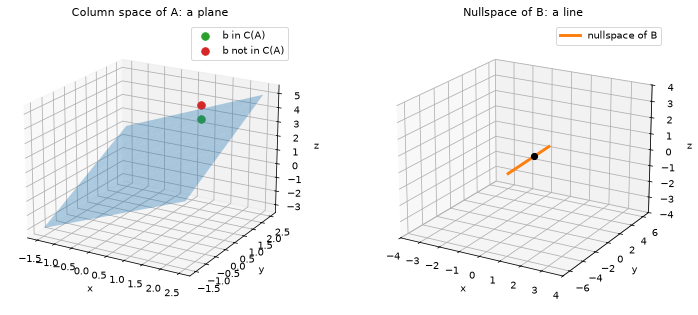

In [4]:
s, t = np.meshgrid(np.linspace(-1.5, 2.5, 12), np.linspace(-1.5, 2.5, 12))
plane = s[..., None] * A[:, 0] + t[..., None] * A[:, 1]     # all combinations of the two columns

# a different matrix, 2 x 3, whose nullspace is a line in R^3
B = np.array([[1, 1, 1],
              [1, 2, 3]])
direction = np.array([1, -2, 1])
print("B @ direction =", B @ direction)
line = np.linspace(-3, 3, 50)[:, None] * direction

fig = plt.figure(figsize=(11, 4.6))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.35, color="C0")
ax1.scatter(*b_in, color="C2", s=60, label="b in C(A)")
ax1.scatter(*b_out, color="C3", s=60, label="b not in C(A)")
ax1.view_init(elev=20, azim=-60)
ax1.set_title("Column space of A: a plane")
ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_zlabel("z"); ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(*line.T, color="C1", lw=3, label="nullspace of B")
ax2.scatter(*direction, color="k", s=40)
ax2.set_xlim(-4, 4); ax2.set_ylim(-7, 7); ax2.set_zlim(-4, 4)
ax2.view_init(elev=20, azim=-60)
ax2.set_title("Nullspace of B: a line")
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("z"); ax2.legend()
plt.tight_layout()
plt.show()

Left: the blue plane is $C(A)$. The green point lies on it, so $A\mathbf{x} = \mathbf{b}$ has a solution; the red point floats above it, so it has none. Right: every vector $\mathbf{x}$ on the orange line satisfies $B\mathbf{x} = \mathbf{0}$.

## 3. Row reduction to $R$ from scratch

We reduce $A$ to its **reduced row echelon form** $R$: pivots equal to 1, zeros above and below every pivot, and zero rows at the bottom. The function prints the matrix after each pivot column.

In [5]:
def rref(A, verbose=False, tol=1e-12):
    """Reduce A to reduced row echelon form. Returns R and the list of pivot columns."""
    R = np.array(A, dtype=float)
    m, n = R.shape
    pivots, row = [], 0
    for col in range(n):
        if row == m:
            break
        below = [i for i in range(row, m) if abs(R[i, col]) > tol]
        if not below:
            continue                                  # no pivot in this column: a free column
        R[[row, below[0]]] = R[[below[0], row]]       # swap a nonzero entry into the pivot spot
        R[row] = R[row] / R[row, col]                 # make the pivot equal to 1
        for i in range(m):
            if i != row:
                R[i] = R[i] - R[i, col] * R[row]      # clear the column above and below
        pivots.append(col)
        row += 1
        if verbose:
            print(f"after pivot in column {col + 1}:\n", R + 0.0)
    return R, pivots


A = np.array([[1, 2, 1, 3],
              [2, 4, 3, 8],
              [3, 6, 4, 11]])
R, pivots = rref(A, verbose=True)
print("pivot columns:", [p + 1 for p in pivots], "(counting from 1)")
print("rank = number of pivots =", len(pivots))

after pivot in column 1:
 [[1. 2. 1. 3.]
 [0. 0. 1. 2.]
 [0. 0. 1. 2.]]
after pivot in column 3:
 [[1. 2. 0. 1.]
 [0. 0. 1. 2.]
 [0. 0. 0. 0.]]
pivot columns: [1, 3] (counting from 1)
rank = number of pivots = 2


In [6]:
sympy_R, sympy_pivots = sp.Matrix(A).rref()
print("SymPy's R:\n", np.array(sympy_R.tolist(), dtype=float))
print("same as ours:", np.allclose(R, np.array(sympy_R.tolist(), dtype=float)), "| same pivots:", list(sympy_pivots) == pivots)

SymPy's R:
 [[1. 2. 0. 1.]
 [0. 0. 1. 2.]
 [0. 0. 0. 0.]]
same as ours: True | same pivots: True


## 4. Special solutions and the nullspace

Each **free column** (no pivot) gives one **special solution**: set that free variable to 1 and the other free variables to 0, then solve for the pivot variables. Reading it off $R$: put the free variable's 1 in its own position, put the negatives of that column's entries in the pivot positions, and zeros elsewhere.

In [7]:
def special_solutions(R, pivots):
    """One special solution per free column, read off R. Returns them as the columns of N."""
    n = R.shape[1]
    free = [j for j in range(n) if j not in pivots]
    N = np.zeros((n, len(free)))
    for k, j in enumerate(free):
        N[j, k] = 1                                   # the free variable
        for row, pivot_col in enumerate(pivots):
            N[pivot_col, k] = -R[row, j]              # the pivot variables
    return N


N = special_solutions(R, pivots)
print("special solutions (one per column):\n", N + 0.0)
print("A @ N =\n", A @ N)

special solutions (one per column):
 [[-2. -1.]
 [ 1.  0.]
 [ 0. -2.]
 [ 0.  1.]]
A @ N =
 [[0. 0.]
 [0. 0.]
 [0. 0.]]


The nullspace is every combination of the special solutions. SciPy's `null_space` finds an *orthonormal* basis (perpendicular vectors of length 1) for the same subspace, so its columns look different. We check that they describe the same set: stacking both bases together should not add any new direction, so the rank stays 2.

In [8]:
Z = sla.null_space(A)
print("scipy basis shape:", Z.shape)
print("A @ Z is zero:", np.allclose(A @ Z, 0))
print("rank of [N | Z] =", np.linalg.matrix_rank(np.hstack([N, Z])), "(still 2, so same subspace)")

scipy basis shape: (4, 2)
A @ Z is zero: True
rank of [N | Z] = 2 (still 2, so same subspace)


## 5. The complete solution to $A\mathbf{x} = \mathbf{b}$

Row reduce the augmented matrix $[A \mid \mathbf{b}]$. Setting every free variable to 0 gives a **particular solution** $\mathbf{x}_p$. Adding any nullspace vector keeps the equation true, so the complete solution is $\mathbf{x} = \mathbf{x}_p + \mathbf{x}_n$.

In [9]:
b = np.array([1, 3, 4])
Rb, piv_b = rref(np.column_stack([A, b]))
print("[R | d] =\n", Rb)

# particular solution: free variables = 0, pivot variables read from the last column
x_p = np.zeros(4)
for row, col in enumerate(piv_b):
    if col < 4:
        x_p[col] = Rb[row, 4]
print("x_p =", x_p, "| A @ x_p =", A @ x_p)

rng = np.random.default_rng(0)
for _ in range(3):
    t = rng.normal(size=2)
    x = x_p + N @ t                                   # add a random nullspace vector
    print("x_p + N t, t =", np.round(t, 2), "-> A @ x =", np.round(A @ x, 6))

# a right-hand side outside the column space: the last row of [R | d] becomes 0 = nonzero
b_bad = np.array([1, 3, 5])
print("\nb = (1, 3, 5): last row of [R | d] is", rref(np.column_stack([A, b_bad]))[0][-1])

[R | d] =
 [[1. 2. 0. 1. 0.]
 [0. 0. 1. 2. 1.]
 [0. 0. 0. 0. 0.]]
x_p = [0. 0. 1. 0.] | A @ x_p = [1. 3. 4.]
x_p + N t, t = [ 0.13 -0.13] -> A @ x = [1. 3. 4.]
x_p + N t, t = [0.64 0.1 ] -> A @ x = [1. 3. 4.]
x_p + N t, t = [-0.54  0.36] -> A @ x = [1. 3. 4.]

b = (1, 3, 5): last row of [R | d] is [0. 0. 0. 0. 1.]


A picture of the same idea in 2D. For $`A = \begin{bmatrix}1 & 2\\2 & 4\end{bmatrix}`$ and $\mathbf{b} = (5, 10)$, the nullspace is a line through the origin and the solution set is a **parallel line** shifted by $\mathbf{x}_p$. Because it misses the origin, the solution set is not a subspace.

A2 @ x_p2 = [ 5 10] | A2 @ n2 = [0 0]


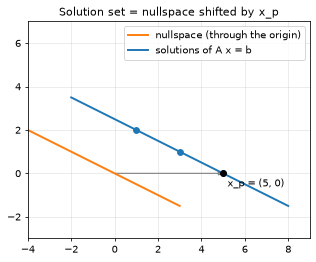

In [10]:
A2 = np.array([[1, 2], [2, 4]])
b2 = np.array([5, 10])
x_p2 = np.array([5, 0])
n2 = np.array([-2, 1])                               # special solution: A2 @ n2 = 0
print("A2 @ x_p2 =", A2 @ x_p2, "| A2 @ n2 =", A2 @ n2)

ts = np.linspace(-1.5, 3.5, 50)[:, None]
null_line = ts * n2
solution_line = x_p2 + ts * n2

fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.plot(*null_line.T, color="C1", lw=2, label="nullspace (through the origin)")
ax.plot(*solution_line.T, color="C0", lw=2, label="solutions of A x = b")
for t in [0, 1, 2]:
    ax.scatter(*(x_p2 + t * n2), color="C0", zorder=3)
ax.scatter(*x_p2, color="k", zorder=4)
ax.annotate("x_p = (5, 0)", x_p2 + [0.2, -0.6])
ax.arrow(0, 0, *x_p2, color="gray", head_width=0.15, length_includes_head=True)
ax.set_xlim(-4, 9); ax.set_ylim(-3, 7)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
ax.set_title("Solution set = nullspace shifted by x_p")
plt.show()

## 6. Four cases by rank

For an $m \times n$ matrix with rank $r$, the numbers $m$, $n$, and $r$ decide how many solutions $A\mathbf{x} = \mathbf{b}$ can have. `numpy.linalg.matrix_rank` counts the pivots for us.

In [11]:
examples = {
    "square, invertible":        np.array([[1, 2], [3, 7]]),
    "tall, full column rank":    np.array([[1, 0], [0, 1], [1, 1]]),
    "wide, full row rank":       np.array([[1, 2, 3], [0, 1, 4]]),
    "neither (rank-deficient)":  np.array([[1, 2, 1, 3], [2, 4, 3, 8], [3, 6, 4, 11]]),
}

print(f"{'matrix':26s} {'m':>2} {'n':>2} {'r':>2}  {'free columns (n-r)':>18}  solutions")
for name, M_ in examples.items():
    m, n = M_.shape
    r = np.linalg.matrix_rank(M_)
    if r == m and r == n:
        verdict = "exactly one, for every b"
    elif r == n:
        verdict = "0 or 1 (solvable only if b is in C(A))"
    elif r == m:
        verdict = "always solvable, infinitely many"
    else:
        verdict = "0 or infinitely many"
    print(f"{name:26s} {m:>2} {n:>2} {r:>2}  {n - r:>18}  {verdict}")

matrix                      m  n  r  free columns (n-r)  solutions
square, invertible          2  2  2                   0  exactly one, for every b
tall, full column rank      3  2  2                   0  0 or 1 (solvable only if b is in C(A))
wide, full row rank         2  3  2                   1  always solvable, infinitely many
neither (rank-deficient)    3  4  2                   2  0 or infinitely many


## 7. A hidden redundant column

In a data matrix, each column is a feature. If one feature is a combination of others, say a third feature computed from the first two, the matrix has a nonzero nullspace, and fitting a model with all three features cannot give a unique answer. The nullspace tells us **which** combination is redundant.

In [12]:
X = np.array([[1, 2, 3],
              [2, 0, 2],
              [0, 1, 1],
              [3, 1, 4]])          # the third column is the first plus the second
y = np.array([6, 4, 2, 8])

print("rank of X:", np.linalg.matrix_rank(X), "(it has 3 columns)")
print("nullspace direction:", sla.null_space(X).ravel())
G = X.T @ X
print("rank of X^T X:", np.linalg.matrix_rank(G), "| determinant:", round(np.linalg.det(G), 6))
try:
    np.linalg.solve(G, X.T @ y)
except np.linalg.LinAlgError as error:
    print("solving the normal equations fails:", error)

rank of X: 2 (it has 3 columns)
nullspace direction: [-0.577 -0.577  0.577]
rank of X^T X: 2 | determinant: 0.0
solving the normal equations fails: Singular matrix


In [13]:
null_dir = sla.null_space(X).ravel()
null_dir = null_dir / null_dir[0]                    # scale so the first entry is 1
print("redundancy relation (weights that cancel out):", np.round(null_dir, 3))

w1 = np.array([1.0, 1.0, 1.0])
w2 = w1 + 2.5 * null_dir                             # a different weight vector
print("w1 =", w1, "w2 =", np.round(w2, 2))
print("same predictions:", np.allclose(X @ w1, X @ w2))

X_fixed = X[:, :2]                                   # drop the redundant column
w = np.linalg.solve(X_fixed.T @ X_fixed, X_fixed.T @ y)
print("with the redundant column removed, the weights are unique:", np.round(w, 3))

redundancy relation (weights that cancel out): [ 1.  1. -1.]
w1 = [1. 1. 1.] w2 = [ 3.5  3.5 -1.5]
same predictions: True
with the redundant column removed, the weights are unique: [2. 2.]


## Recap and next steps

* A **subspace** contains $\mathbf{0}$ and is closed under addition and scaling. The column space $C(A)$ is all combinations of the columns, and $A\mathbf{x} = \mathbf{b}$ is solvable exactly when $\mathbf{b}$ is in $C(A)$.
* The **nullspace** $N(A)$ holds every $\mathbf{x}$ with $A\mathbf{x} = \mathbf{0}$. We find it by row reducing to $R$ and reading one **special solution** per free column.
* The **complete solution** is $\mathbf{x}_p + \mathbf{x}_n$: a shifted copy of the nullspace, which is not a subspace unless $\mathbf{b} = \mathbf{0}$.
* The rank $r$ (the number of pivots) and the shape $m \times n$ decide between one solution, none, or infinitely many.
* A redundant feature shows up as a nonzero nullspace, and then the model weights are not unique.

**Try it yourself:** change `b` in section 5 to other vectors and predict, before you run it, whether the last row of $[R \mid \mathbf{d}]$ becomes $0 = 0$ or $0 = $ nonzero. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Independence, Basis, and Dimension](../independence-basis-and-dimension/README.md).